# Multi-map navigation by bundling and binding (Fig. 5)

Reproduces Fig. 5 (Sec. 3.3, Appendix L): the reward maps of two contexts stored in one
population, retrieved by querying with the right context, and navigated by gradient ascent.

**Bundling** (App. L.1) averages the representations of the rewarded locations of one context
into a memory, $p_R(s) = \frac{1}{N_R}\sum_i p(r_i, s)$. Querying it with the current state,
$C_R(r, s) = p(r, s)^\top p_R(s)$, gives a sum of one similarity function per reward. With
Gaussian eigenvalues for both spatial generators the similarity function is a Gaussian, so the
reward map is a mixture of Gaussians. **Binding** (App. L.2) is remapping: the context
generator makes the maps of the two contexts nearly orthogonal, so their memories can be summed
into one vector (Eq. 9) and retrieved separately by querying with the right $s$.

Three rewards as in Fig. 5, two food items in one context and one home in the other. $N = 300$
is the figure caption and the context shift $s = 0 \to 5$ is Appendix A. The arena is
$[-3, 3]$, so that the rewards sit more than one similarity width apart.

The queried map is a sum of similarity functions and does not depend on the mixing matrix $R$.
It does depend on the eigenvalues, which were drawn without a seed when the figure was made, so
they are kept in `data/reward_navigation_spectra.npz` and the maps below are those of the
paper. `SEED` fixes $R$. The maps are drawn as in the paper, with $y$ increasing downward.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.generators import block_diag_skew, build_generators_with_context
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import RemappingModel
from expmap.navigation import bind, bundle, query, similarity_gradient

ARENA_SIZE = 3.0
BINS = 32
S_FOOD, S_HOME = 0.0, 5.0
SEED = 0

# Reward sites, as the rate map bins of the printed figure.
FOOD_BINS = [(25, 16), (10, 5)]
HOME_BINS = [(7, 27)]

START = torch.tensor([0.3, 1.1])  # one bin inside the basin of the first food item from the printed start, bin (16, 22)
ETA, N_STEPS = 0.3, 40
PLOT_EVERY = 4  # steps between the drawn markers

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2
FOOD = torch.tensor([[centers[i], centers[j]] for i, j in FOOD_BINS], dtype=torch.float32)
HOME = torch.tensor([[centers[i], centers[j]] for i, j in HOME_BINS], dtype=torch.float32)
EXTENT = (-ARENA_SIZE, ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE)  # y downward, as in the printed figure

In [2]:
spectra = np.load(REPO_ROOT / "data" / "reward_navigation_spectra.npz")
sigma_x, sigma_y, sigma_s = (block_diag_skew(spectra[key]) for key in ("lambda_x", "lambda_y", "lambda_s"))
N = len(sigma_x)

R = random_orthogonal_matrix(N, seed=SEED)
p0 = starting_state(R)
Gx, Gy, Gs = build_generators_with_context(sigma_x, sigma_y, sigma_s, R)
model = RemappingModel(Gx, Gy, Gs)

for name, G in [("Gx", Gx), ("Gy", Gy), ("Gs", Gs)]:
    assert torch.allclose(G, -G.T, atol=1e-6), f"{name} must be skew-symmetric"
assert torch.allclose(Gx @ Gs, Gs @ Gx, atol=1e-5), "Gs must commute with Gx"

print(f"N = {N} units")

N = 300 units


In [3]:
# The maps are evaluated at the bin centers, so the reward markers land on their bins.
X, Y = np.meshgrid(centers, centers, indexing="ij")
grid = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)

with torch.no_grad():
    p_food_context = model(grid, p0, context=S_FOOD)
    p_home_context = model(grid, p0, context=S_HOME)

print(f"||p|| = {p_food_context.norm(dim=1).mean():.6f}")

||p|| = 1.000000


In [4]:
# Bundle within a context (App. L.1), bind across contexts (Eq. 9), query at every location.
with torch.no_grad():
    memory_food = bundle(model(FOOD, p0, context=S_FOOD))
    memory_home = bundle(model(HOME, p0, context=S_HOME))
    composite = bind([memory_food, memory_home])

    landscape_food = query(p_food_context, composite).numpy().reshape(BINS, BINS)
    landscape_home = query(p_home_context, composite).numpy().reshape(BINS, BINS)

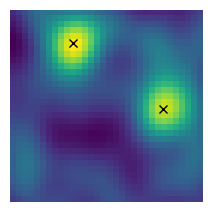

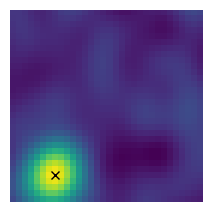

In [5]:
# Fig. 5 b and c: the composite memory queried in the food context and in the home context.
for landscape, sites, name in [
    (landscape_food, FOOD, "pc_rewarded_ratemap1"),
    (landscape_home, HOME, "pc_rewarded_ratemap2"),
]:
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(landscape.T, extent=EXTENT)
    plt.plot(sites[:, 0], sites[:, 1], "kx")
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

ended 0.033 from the nearest food item


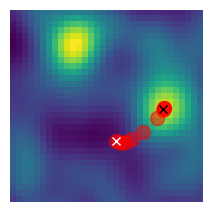

In [6]:
# Fig. 5 d: gradient ascent on the retrieved map, r <- r + eta * grad C_R (App. L.1), with the
# gradient in closed form.
position = START.clone()
trajectory = [position.clone()]

for _ in range(N_STEPS):
    gradient = similarity_gradient(model, position, composite, p0, context=S_FOOD)
    position = torch.clamp(position + ETA * gradient, -ARENA_SIZE, ARENA_SIZE)
    trajectory.append(position.clone())

trajectory = torch.stack(trajectory).numpy()

plt.figure(figsize=(2.5, 2.5))
plt.imshow(landscape_food.T, extent=EXTENT)
plt.plot(trajectory[::PLOT_EVERY, 0], trajectory[::PLOT_EVERY, 1], "or", alpha=0.5, markersize=10)
plt.plot(*START, "wx")
plt.plot(*FOOD[0], "kx")
plt.axis("off")
plt.savefig(FIGURE_DIR / "reward_gradient_navigation.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "reward_gradient_navigation.png", dpi=300, bbox_inches="tight")

print(f"ended {np.linalg.norm(FOOD.numpy() - trajectory[-1], axis=1).min():.3f} from the nearest food item")

## Retrieval by context

The composite memory queried at each reward site, in each context. A site scores high in its
own context and low in the other. The Gaussian similarity of $N/2 = 150$ eigenvalues has a
ripple of about $1/\sqrt{N/2}$ (App. I), which the signal $e^{-d^2}$ exceeds out to a distance
of about 1.6. Beyond that, gradient ascent climbs a ripple instead, which is why the start
point above lies within that distance of a food item.

In [7]:
sites = {"food 1": FOOD[0], "food 2": FOOD[1], "home": HOME[0]}
for context, label in [(S_FOOD, "food"), (S_HOME, "home")]:
    with torch.no_grad():
        scores = {name: query(model(site[None], p0, context=context)[0], composite).item() for name, site in sites.items()}
    print(f"context {label}: " + "  ".join(f"{name} {score:+.3f}" for name, score in scores.items()))

ripple = 1 / np.sqrt(N // 2)
print(f"ripple 1/sqrt(N/2) = {ripple:.3f}, signal above it out to d = {np.sqrt(-np.log(ripple)):.1f}")

context food: food 1 +0.533  food 2 +0.584  home +0.010
context home: food 1 +0.062  food 2 -0.028  home +1.006
ripple 1/sqrt(N/2) = 0.082, signal above it out to d = 1.6
